# Цель работы

Построить нечёткую модель оценки источников бесперебойного питания.

# Задачи

Определить входные и выходные лингвистические переменные, функции принадлежности и полную базу из 27 правил. Реализация вывода Мамдани и проверка системы продолжаются в лабораторной работе 5.

# Ход работы

Используются мощность (Вт), время автономной работы (мин) и шум (дБ). Выход — учебный рейтинг от 0 до 100. Пороговые значения заданы для демонстрации алгоритма и не являются измерениями оборудования.

In [1]:
from fuzzy import membership, output_terms, domains, rules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Функции принадлежности

Крайние термы имеют форму плеча, поэтому граничные значения принадлежат соответствующему терму со степенью 1. Между термами есть перекрытия; одному значению могут соответствовать несколько ненулевых степеней принадлежности.

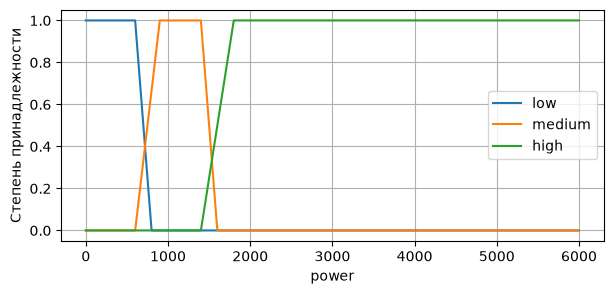

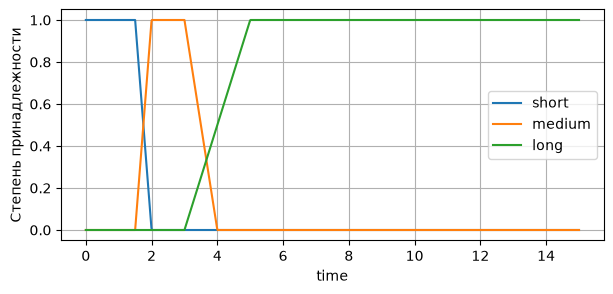

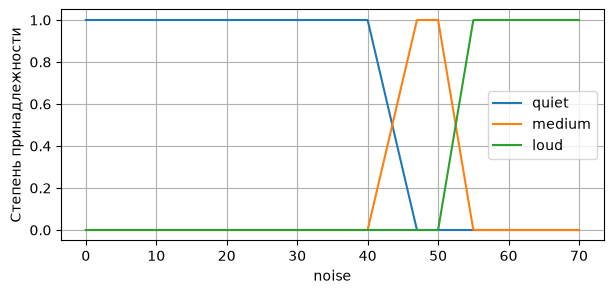

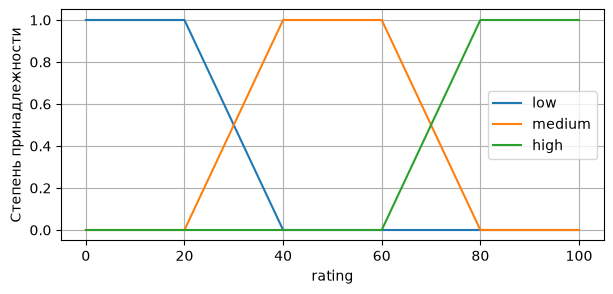

In [2]:
#| fig-cap: ["Термы мощности", "Термы времени автономной работы", "Термы уровня шума", "Термы выходного рейтинга"]
for name, terms in list(membership.items()) + [("rating", output_terms)]:
    bounds = domains.get(name, (0,100))
    x = np.linspace(*bounds, 1001)
    fig, ax = plt.subplots(figsize=(7,3))
    for term, fn in terms.items(): ax.plot(x, fn(x), label=term)
    ax.set(xlabel=name, ylabel="Степень принадлежности", ylim=(-0.05,1.05))
    ax.legend(); ax.grid(); plt.show()


## База правил

Мощность и автономность повышают рейтинг, шум снижает его. Каждому из трёх термов приписана порядковая оценка 0, 1 или 2, где 2 соответствует лучшему значению. Сумма до 1 даёт низкий рейтинг, от 2 до 3 — средний, от 4 — высокий. Это экспертная эвристика учебной модели.

In [3]:
#| tbl-cap: "Полная база нечётких правил"
assert len(rules) == len(set(r[:3] for r in rules)) == 27
for name, terms in membership.items():
    x = np.linspace(*domains[name], 1001)
    assert np.all(np.max([fn(x) for fn in terms.values()], axis=0) > 0)
pd.DataFrame(rules, columns=["power", "time", "noise", "rating"])


,power,time,noise,rating
0,low,short,loud,low
1,low,short,medium,low
2,low,short,quiet,medium
3,low,medium,loud,low
4,low,medium,medium,medium
5,low,medium,quiet,medium
6,low,long,loud,medium
7,low,long,medium,medium
8,low,long,quiet,high
9,medium,short,loud,low


# Выводы

Составлена полная база из 27 правил и заданы четыре лингвистические переменные. Проверка сеткой подтверждает отсутствие непокрытых участков входных диапазонов. В отличие от чёткого выбора терма, модель сохраняет все степени принадлежности для следующего этапа вывода.